# Trained reader: full validation and recipe selection

This notebook replays the **actual audited cloud results**. Training and neural inference ran on Kaggle; the cells below inspect their saved measurements and reproduce plots. All four inference policies were evaluated on the same 2,372 validation questions across 54 stories. No test scores select the policy.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
root = Path.cwd()
if not (root / 'docs').exists():
    root = root.parent
read = lambda name: json.loads((root / 'docs' / name).read_bytes())
validation = read('final-validation.json')
training = read('full-generator-training.json')
checkpoints = read('full-generator-validation.json')
assert validation['questions'] == 2372
assert training['training_complete'] and not training['test_accessed']
print(validation['cohort'])
print('Selected:', validation['selected_arm'])

{'training_questions': 7883, 'validation_questions': 2372, 'sealed_test_questions': 325}
Selected: reranked_windows


## Training trajectory

The generator saw all 7,883 training annotations for three epochs. Loss and held-out answer quality measure different things: the last validation gains are small even though training loss keeps falling. The checkpoint rule compares every required epoch on the complete validation cohort.

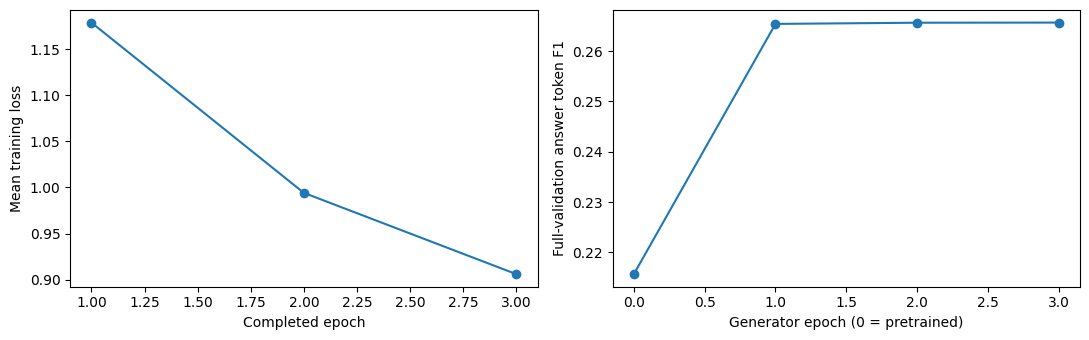

Epoch 0: F1=0.215675, EM=0.099916, n=2372
Epoch 1: F1=0.265383, EM=0.141653, n=2372
Epoch 2: F1=0.265618, EM=0.140809, n=2372
Epoch 3: F1=0.265647, EM=0.141653, n=2372


In [2]:
epochs = [r['epoch'] for r in training['checkpoints'] if r['mean_train_loss'] is not None]
loss = [r['mean_train_loss'] for r in training['checkpoints'] if r['mean_train_loss'] is not None]
curve = sorted(checkpoints['candidates'], key=lambda r: r['epoch'])
assert all(r['validation']['n'] == 2372 for r in curve)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(epochs, loss, marker='o'); axes[0].set(xlabel='Completed epoch', ylabel='Mean training loss')
axes[1].plot([r['epoch'] for r in curve], [r['validation']['f1'] for r in curve], marker='o')
axes[1].set(xlabel='Generator epoch (0 = pretrained)', ylabel='Full-validation answer token F1')
fig.tight_layout(); plt.show()
for r in curve:
    print(f"Epoch {r['epoch']}: F1={r['validation']['f1']:.6f}, EM={r['validation']['em']:.6f}, n={r['validation']['n']}")

## Retrieval and context comparison

`standard` uses supplied sections directly. `windows` assembles question-matched source windows under the frozen 512-token input budget. The trained cross-encoder reranks BM25 candidates. Every arm uses the selected generator and the same deterministic beam-search settings.

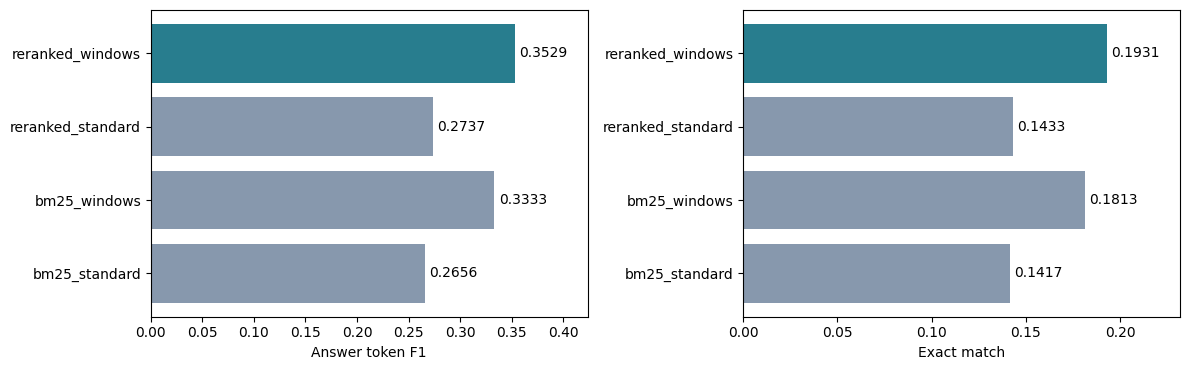

bm25_standard {'f1': 0.2656467270660276, 'em': 0.14165261382799327, 'citation_validity': 1.0}
bm25_windows {'f1': 0.3332797225968603, 'em': 0.1812816188870152, 'citation_validity': 1.0}
reranked_standard {'f1': 0.27368857336037894, 'em': 0.1433389544688027, 'citation_validity': 1.0}
reranked_windows {'f1': 0.3528916649753075, 'em': 0.19308600337268128, 'citation_validity': 1.0}


In [3]:
metrics = validation['metrics']
labels = list(metrics)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, title in zip(axes, ['f1', 'em'], ['Answer token F1', 'Exact match']):
    values = [metrics[name][metric] for name in labels]
    bars = ax.barh(labels, values, color=['#8798ad'] * 3 + ['#287d8e'])
    ax.bar_label(bars, fmt='%.4f', padding=3); ax.set(xlabel=title, xlim=(0, max(values)*1.2))
fig.tight_layout(); plt.show()
for name, values in metrics.items():
    print(name, values)
assert validation['selected_arm'] == max(labels, key=lambda name: metrics[name]['f1'])

## Evidence and reproducibility

The independent replay authenticates all 38 paired shards, reconstructs source windows and token budgets, checks source offsets, recomputes answer/evidence metrics, and repeats the predeclared story bootstrap. Citation validity checks quoted source spans; it does not establish that an answer is entailed. Validation results are model-selection evidence, not an independent replication.

In [4]:
assert all(validation['independent_audit'].values())
assert all(m['citation_validity'] == 1.0 for m in metrics.values())
print('Questions:', validation['questions'], 'Stories:', validation['stories'])
print('Generator epoch:', validation['generator_epoch'])
print('Reranker epoch:', validation['reranker_epoch'])
print('Package contract:', validation['package_contract_sha256'])
print('Cloud validation:', validation['validation_kernel'])
print('Cloud package:', validation['package_kernel'])

Questions: 2372 Stories: 54
Generator epoch: 3
Reranker epoch: 1
Package contract: a3148b684777e34db0c814f27d0f5d24f8437d9f17dbe1c9c466c64f83fd6ff1
Cloud validation: aikyatansinha/portfolio-rag-full-joint-comparison-v1/2
Cloud package: aikyatansinha/audited-narrative-production-package/1


The source-family partition differs from the official FairytaleQA benchmark. Story identity is supplied, and these scores do not measure global book routing, adult literary interpretation, or unknown-question calibration. The separate sealed-test notebook is populated only after the one-shot full-cohort audit finishes.